Question 1 MTH 348 Homework

In [22]:
# imports
import math
import timeit
import numpy as np
import pandas as pd
import scipy.linalg
from sklearn import metrics
import matplotlib.pyplot as plt 

In [6]:
def regr_metrics(act, pred):
    return (math.sqrt(metrics.mean_squared_error(act, pred)), 
     metrics.mean_absolute_error(act, pred))

In [7]:
def scipylstq(A, b):
    return scipy.linalg.lstsq(A,b)[0]

In [8]:
row_names = ['Normal Eqns- Naive',
             'Normal Eqns- Cholesky', 
             'QR Factorization', 
             'SVD', 
             'Scipy lstsq']

name2func = {'Normal Eqns- Naive': 'ls_naive', 
             'Normal Eqns- Cholesky': 'ls_chol', 
             'QR Factorization': 'ls_qr',
             'SVD': 'ls_svd',
             'Scipy lstsq': 'scipylstq'}

In [9]:
def ls_naive(A, b):
     return np.linalg.inv(A.T @ A) @ A.T @ b

def ls_chol(A, b):
    R = scipy.linalg.cholesky(A.T @ A)
    w = scipy.linalg.solve_triangular(R, A.T @ b, trans='T')
    return scipy.linalg.solve_triangular(R, w)

def ls_qr(A,b):
    Q, R = scipy.linalg.qr(A, mode='economic')
    return scipy.linalg.solve_triangular(R, Q.T @ b)

def ls_svd(A,b):
    m, n = A.shape
    U, sigma, Vh = scipy.linalg.svd(A, full_matrices=False, lapack_driver='gesdd')
    w = (U.T @ b)/ sigma
    return Vh.T @ w

In [10]:
m_array = np.array([100, 1000, 10000])
n_array = np.array([20, 100, 1000])

In [11]:
index = pd.MultiIndex.from_product([m_array, n_array], names=['# rows', '# cols'])

In [12]:
pd.options.display.float_format = '{:,.6f}'.format
df = pd.DataFrame(index=row_names, columns=index)
df_error = pd.DataFrame(index=row_names, columns=index)

In [13]:
# %%prun
for m in m_array:
    for n in n_array:
        if m >= n:        
            x = np.random.uniform(-10,10,n)
            A = np.random.uniform(-40,40,[m,n])   # removed np.asfortranarray
            b = np.matmul(A, x) + np.random.normal(0,2,m)
            for name in row_names:
                fcn = name2func[name]
                t = timeit.timeit(fcn + '(A,b)', number=5, globals=globals())
                df.loc[name, [(m,n)]] = t
                coeffs = locals()[fcn](A, b)
                reg_met = regr_metrics(b, A @ coeffs)
                df_error.at[name, (m,n)] = reg_met[0]

In [14]:
df

# rows                   100                    1000                     \
# cols                    20       100  1000     20       100      1000   
Normal Eqns- Naive    0.000375 0.110252  NaN 0.000476 0.021522 0.386641   
Normal Eqns- Cholesky 0.001340 0.001532  NaN 0.000814 0.002536 0.106732   
QR Factorization      0.000739 0.003795  NaN 0.003407 0.046595 2.069530   
SVD                   0.001596 0.015998  NaN 0.004086 0.104030 1.985716   
Scipy lstsq           0.001555 0.008355  NaN 0.002632 0.033955 0.854768   

# rows                   10000                     
# cols                    20       100       1000  
Normal Eqns- Naive    0.004874 0.042582  1.527154  
Normal Eqns- Cholesky 0.001957 0.017692  0.386083  
QR Factorization      0.014763 0.241099  5.671994  
SVD                   0.021192 0.285685 11.559289  
Scipy lstsq           0.012164 0.168656  3.357031

Question 4 MTH 348 Homework #4

Create a synthetic matrix using smooth functions, for example Ai,j=sin(xi)cos(yj)+0.5cos(2xi)sin(yj).

a. Compute the SVD.  
b. Plot singular values.   
c. Construct rank-1, rank-2, rank-5, and rank-10 approximations.  
d. Compare approximation errors.  

In [18]:
# Creating synthetic matrix using smooth function
n = 100
x_coords = np.linspace(0, 2 * np.pi, n) 
y_coords = np.linspace(0, 2 * np.pi, n) 

# Numpy broadcasting here instead of nested for loops (idea taken from AI)
X = x_coords[:, np.newaxis] 
Y = y_coords[np.newaxis, :]

A = np.sin(X) * np.cos(Y) + (0.5 * np.cos(2 * X) * np.sin(Y))

In [ ]:
# Part A.) Comptuting SVD
U, s, Vt = np.linalg.svd(A, full_matrices=False)

print("U:", U.shape)
print("s:", s.shape)
print("Vt:", Vt.shape)

print("First 10 singular values:", s[:10])

"""
    An interesting takeaway I found from this is that the first two singular values are 
    significantly larger than 0 and then the last 8 are close to 0. This makes sense b/c
    we can write the first term as a outer product with rank at most 1 and the second term
    as well with rank at most 1. Which means the maximum rank of this matrix is 2.
    Now that also means there is only 2 values that are not very close to 0.
"""

U: (100, 100)
s: (100,)
Vt: (100, 100)
First 10 singular values: [4.99974999e+01 2.49987500e+01 7.11304081e-15 4.94604357e-15
 4.94604357e-15 4.94604357e-15 4.94604357e-15 4.94604357e-15
 4.94604357e-15 4.94604357e-15]


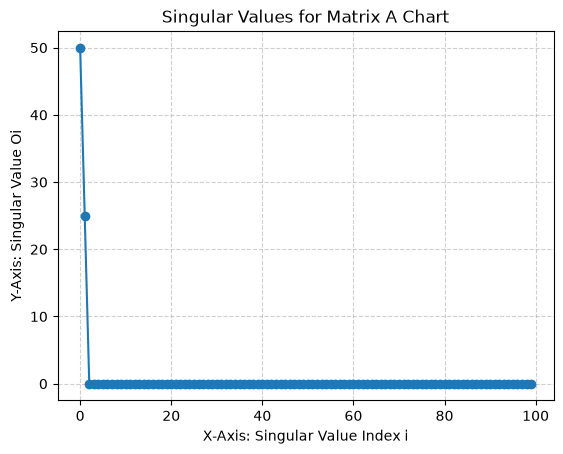

In [25]:
# Part b.) Plotting the singular values
plt.plot(s, marker="o")
plt.title("Singular Values for Matrix A Chart")
plt.xlabel("X-Axis: Singular Value Index i")
plt.ylabel("Y-Axis: Singular Value Oi")
plt.grid(True, linestyle='--', alpha=0.6)
plt.show()

In [29]:
# Part c.) Construct rank-1, rank-2, rank-5, and rank-10 approximations.
A1 = s[0] * np.outer(U[:, 0], Vt[0, :])
A2 = A1 + s[1] * (np.outer(U[:, 1], Vt[1, :]))

# In general we can get a rank k approximation by A = Uk @ SigmaK @ VkT
k = 5
A5 = U[:, :k] @ np.diag(s[:k]) @ Vt[:k, :]

k = 10
A10 = U[:, :k] @ np.diag(s[:k]) @ Vt[:k, :]

In [30]:
# Part d.) Comparing approximation errors using frobenius norms
error_1 = np.linalg.norm(A - A1, ord="fro")
error_2 = np.linalg.norm(A - A2, ord="fro")
error_5 = np.linalg.norm(A - A5, ord="fro")
error_10 = np.linalg.norm(A - A10, ord="fro")

errors = {
    1: error_1,
    2: error_2,
    5: error_5,
    10: error_10
}

print(f"{'Rank (k)':<12} {'Frobenius Error':>20}")
print("-" * 35)

for k, error in errors.items():
    print(f"{k:<12} {error:>20.6e}")

Rank (k)          Frobenius Error
-----------------------------------
1                    2.499875e+01
2                    3.904726e-14
5                    4.026795e-14
10                   4.170797e-14
